# Study 9: why is the fitted length-scale larger than the old run?

The refactor's study-9 fit gives **ls ≈ 0.98** (smooth, near-flat coherence field). An old
committed run had **ls ≈ 0.205** with a visually dramatic, localized field. This notebook shows
that the difference is a **ls ↔ beta trade-off / under-identification**, not a refactor artifact.

Already established:
- Objective is byte-identical old vs new (old code == new code log-lik at fixed params; new code +
  old params reproduces the old field exactly).
- ls prior / VBMC box / LS_FLAT / embedding geometry are byte-identical old vs new.

This notebook is a **read-only diagnostic** — it does not modify inference.py, the fitting script,
or the committed study9-fit posteriors.

**Two parts:**
- **A.** Render the coherence field for several known parameter sets (old committed, old-code
  restarts, new fit). Because the field depends only on params (not code), these are instant.
- **B.** Map the log Z landscape and the field-swing surface over (ls, beta), overlaying the known
  solutions, to show the trade-off ridge.


In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys; sys.path.insert(0, ".")
import json
import numpy as np
import matplotlib.pyplot as plt
import inference as inf

geom = inf.load_geometry()
J = geom['J']
responses_cond, _ = inf.load_responses('../../data/study9_prereg.csv')
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in inf.CONDITIONS}
N_cond   = {c: int(np.array(responses_cond[c]).shape[0]) for c in inf.CONDITIONS}
print("conditions:", inf.CONDITIONS)


conditions: ['physical', 'diet', 'personality', 'heterogeneous']


## A. Coherence fields for known parameter sets

Each entry is a (ls, mu_0, sigma, beta) solution observed this session. `old committed` is the
ls=0.205/beta=16 fit whose field looked "nuanced"; the `old restart` sets are the SAME old code
re-run (varied seed) — note they have small-ish ls too but LOW beta. `new seeded` is the current
fit. Watch the field SWING (max-min of P(kind-linked)) in each title.

In [2]:
# (ls, mu_0, sigma, beta) -- observed this session (study-9 prereg, 4-D free-beta)
PARAM_SETS = {
    'old committed  (ls=0.21, beta=16)': (0.205, -0.397, 0.782, 16.035),
    'old restart A  (ls=2.10, beta=0.83)': (2.10,  -0.921, 1.075, 0.828),
    'old restart B  (ls=0.78, beta=0.38)': (0.78,   0.170, 0.458, 0.380),
    'old restart C  (ls=0.43, beta=0.36)': (0.43,   0.193, 0.464, 0.356),
    'new seeded     (ls=0.98, beta=0.91)': (0.978,  0.006, 0.526, 0.907),
}

all_x = np.vstack([np.array(geom['x_test'])] + [np.array(geom['x_train_cond'][c]) for c in inf.CONDITIONS])
pad = 0.08
(x_lo, y_lo), (x_hi, y_hi) = all_x.min(0) - pad, all_x.max(0) + pad
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 70), np.linspace(y_lo, y_hi, 70))
X_grid = np.column_stack([gx.ravel(), gy.ravel()])
x_test_np = np.array(geom['x_test'])

def field_swings(theta):
    ls, mu, sig, beta = theta
    return {c: float(np.ptp(inf.gp_coherence_field(geom, c, ls, mu, sig, x_test_np, beta_speaker=beta)))
            for c in inf.CONDITIONS}

print(f"{'param set':38s} " + "  ".join(f"{c[:4]:>6}" for c in inf.CONDITIONS))
for name, theta in PARAM_SETS.items():
    sw = field_swings(theta)
    print(f"{name:38s} " + "  ".join(f"{sw[c]:6.3f}" for c in inf.CONDITIONS))
print("\n(field swing = max-min of P(kind-linked) at the test features; bigger = more 'nuanced' looking)")


param set                                phys    diet    pers    hete


old committed  (ls=0.21, beta=16)       0.336   0.361   0.343   0.102
old restart A  (ls=2.10, beta=0.83)     0.011   0.012   0.009   0.005
old restart B  (ls=0.78, beta=0.38)     0.006   0.006   0.005   0.002
old restart C  (ls=0.43, beta=0.36)     0.012   0.014   0.012   0.005
new seeded     (ls=0.98, beta=0.91)     0.011   0.013   0.010   0.005

(field swing = max-min of P(kind-linked) at the test features; bigger = more 'nuanced' looking)


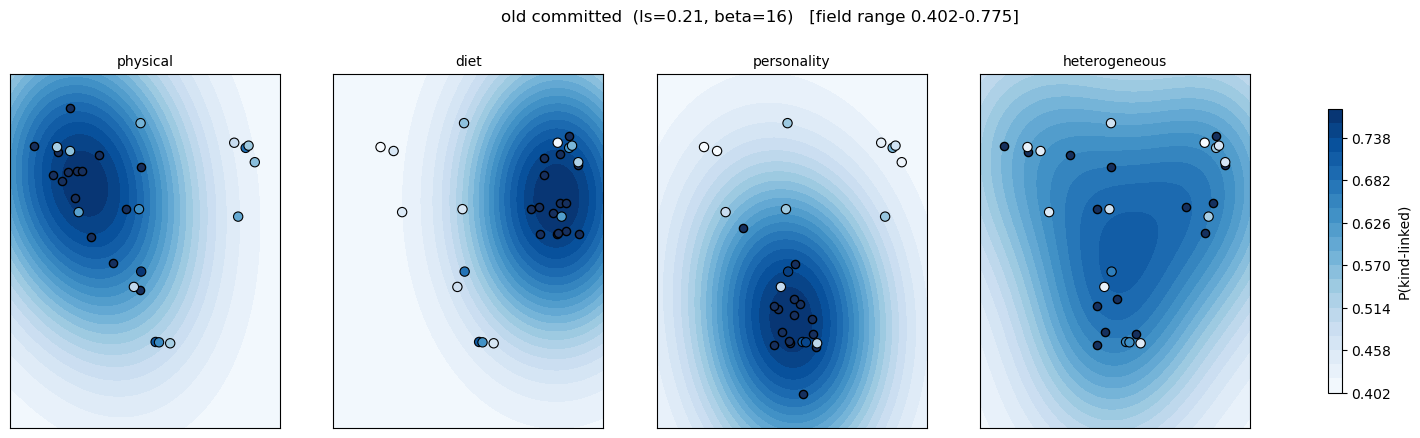

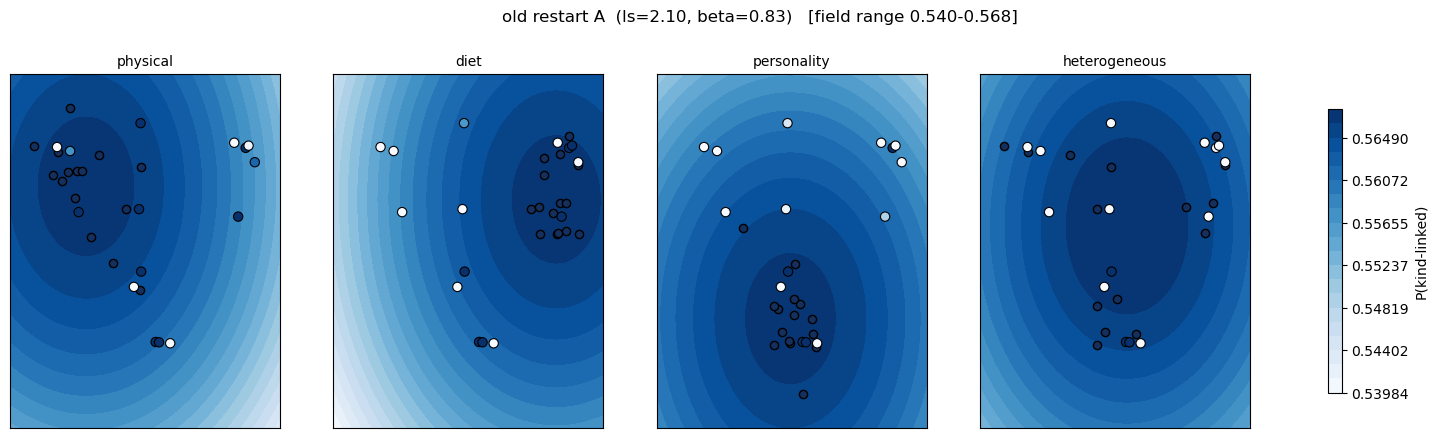

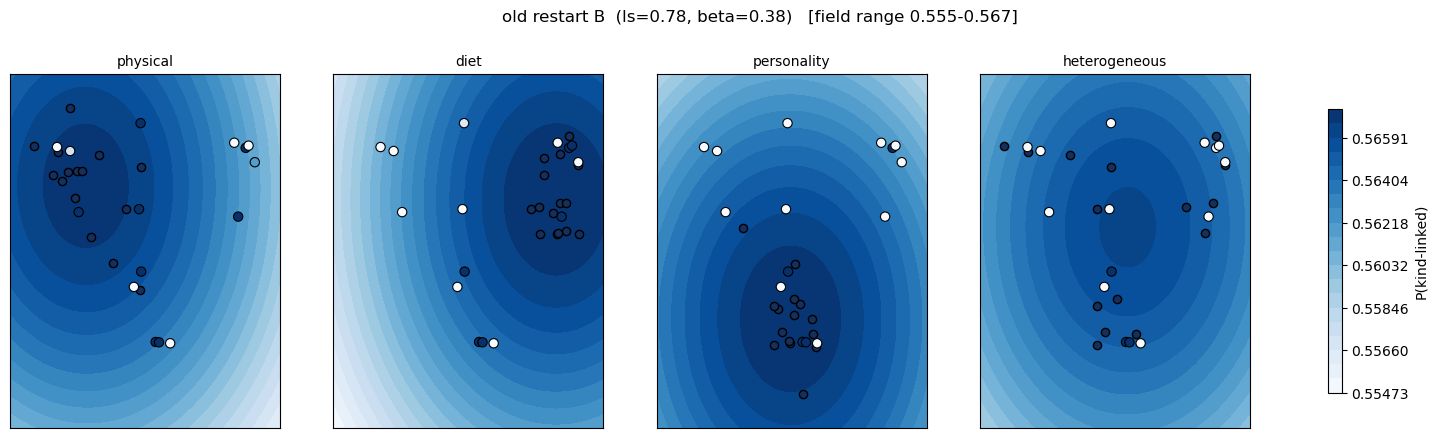

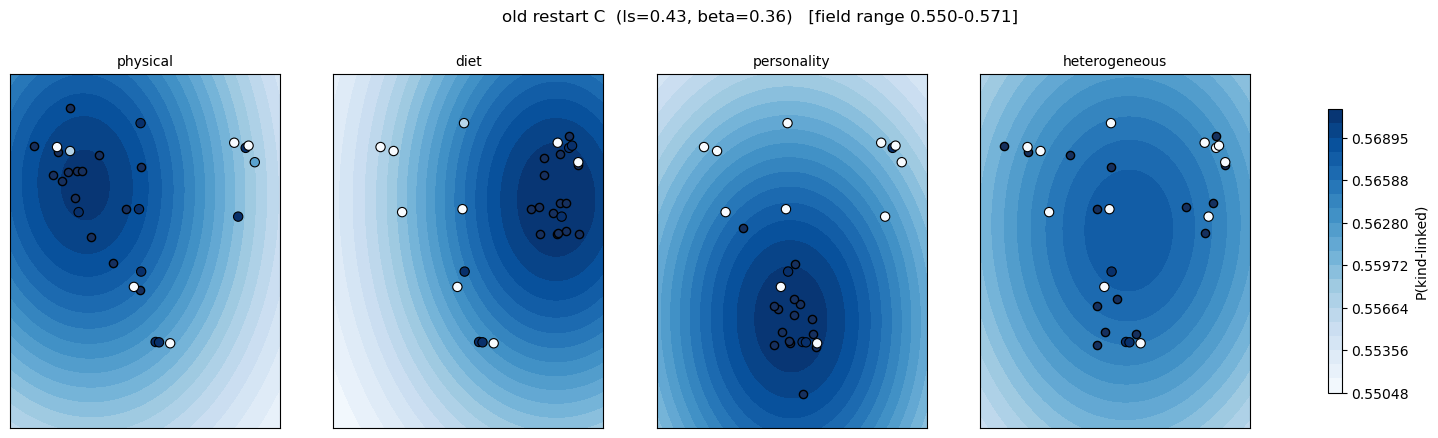

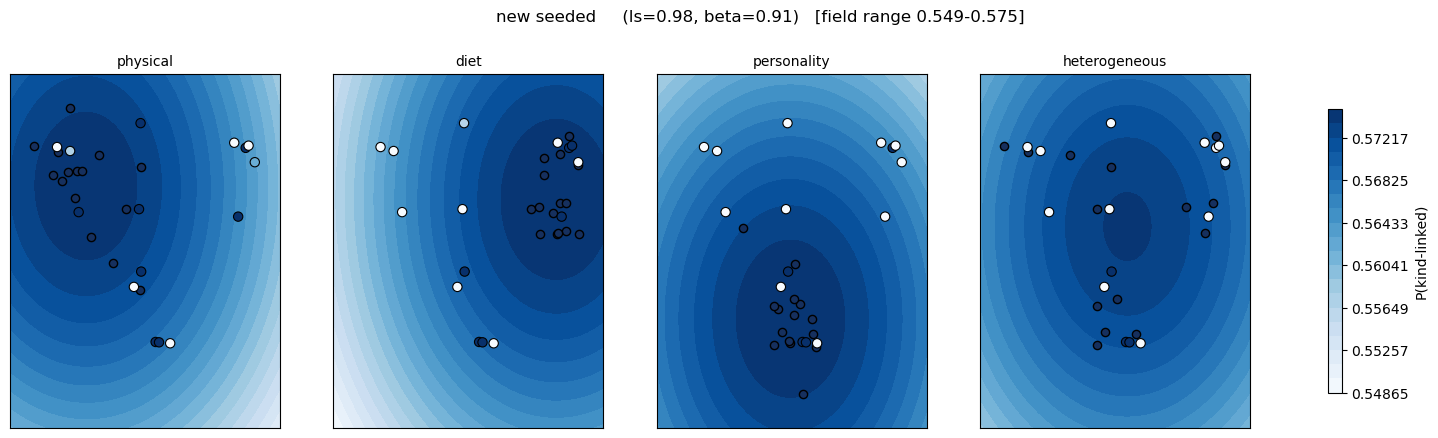

In [3]:
def plot_field_row(name, theta):
    "One row: 4 conditions for a single parameter set, shared color scale across the row."
    ls, mu, sig, beta = theta
    fields = {c: inf.gp_coherence_field(geom, c, ls, mu, sig, X_grid, beta_speaker=beta).reshape(gx.shape)
              for c in inf.CONDITIONS}
    vmin = min(f.min() for f in fields.values()); vmax = max(f.max() for f in fields.values())
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
    for ax, c in zip(axes, inf.CONDITIONS):
        cs = ax.contourf(gx, gy, fields[c], levels=np.linspace(vmin, vmax, 21), cmap='Blues')
        x_tr = np.array(geom['x_train_cond'][c])
        ax.scatter(x_tr[:,0], x_tr[:,1], s=35, color='#16305e', edgecolor='k', zorder=3)
        ax.scatter(x_test_np[:,0], x_test_np[:,1], s=45, c=emp_cond[c], cmap='Blues',
                   norm=cs.norm, edgecolor='k', linewidth=0.8, zorder=3)
        ax.set_title(f"{c}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(cs, ax=axes.ravel().tolist(), shrink=0.8, label='P(kind-linked)')
    fig.suptitle(f"{name}   [field range {vmin:.3f}-{vmax:.3f}]", fontsize=12, y=1.02)
    plt.show()

for name, theta in PARAM_SETS.items():
    plot_field_row(name, theta)


### Takeaway from Part A

Compare the field ranges. The `old committed` (beta=16) row has a wide range (dramatic field). ALL
the other rows — including old-code restarts with SMALL ls (0.43, 0.78) — are nearly flat. So the
"nuance" tracks **beta**, not ls: the old dramatic field was a beta=16 artifact, and small ls alone
(at low beta) does NOT reproduce it.

## B. The (ls, beta) landscape

Left: summed **log Z** over (ls, beta) at the new fit's mu_0/sigma — where do the DATA put weight?
Right: **field swing** (visual nuance) over the same grid — what would each combo LOOK like.
Known solutions overlaid. The log Z ridge shows which (ls, beta) the data actually support; the
swing surface shows they'd look dramatic only in the high-beta / low-ls corner.

In [4]:
MU0, SIG = 0.006, 0.526   # new fit's mu_0, sigma (hold fixed for the slice)
ls_grid   = np.geomspace(0.1, 3.0, 12)
beta_grid = np.geomspace(0.3, 20.0, 12)

logZ = np.zeros((len(ls_grid), len(beta_grid)))
swing = np.zeros_like(logZ)
xt = np.array(geom['x_test'])
for i, ls in enumerate(ls_grid):
    for j, beta in enumerate(beta_grid):
        logZ[i, j] = inf.total_log_lik_free_shapes(geom, responses_cond, float(ls), MU0, SIG, beta_speaker=float(beta))
        sw = [np.ptp(inf.gp_coherence_field(geom, c, float(ls), MU0, SIG, xt, beta_speaker=float(beta)))
              for c in inf.CONDITIONS]
        swing[i, j] = np.mean(sw)
print("landscape computed:", logZ.shape)
print(f"logZ range: [{logZ.min():.0f}, {logZ.max():.0f}]  argmax at ls={ls_grid[np.unravel_index(logZ.argmax(),logZ.shape)[0]]:.2f}, beta={beta_grid[np.unravel_index(logZ.argmax(),logZ.shape)[1]]:.2f}")


landscape computed: (12, 12)
logZ range: [713, 989]  argmax at ls=0.87, beta=0.94


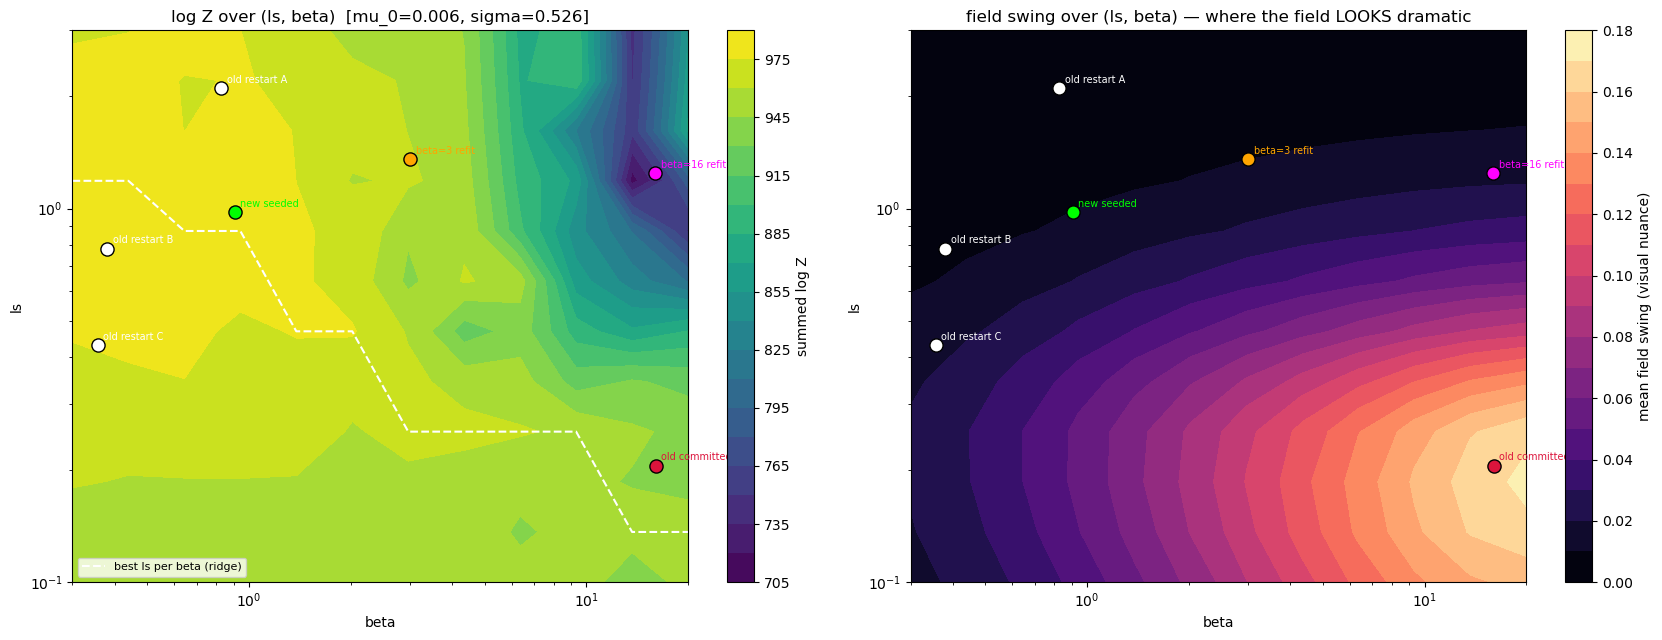

logZ at each solution (interp not exact grid):


  old committed    ls= 0.20 beta= 16.04  logZ=960.7


  new seeded       ls= 0.98 beta=  0.91  logZ=988.8


  old restart A    ls= 2.10 beta=  0.83  logZ=986.3


  old restart B    ls= 0.78 beta=  0.38  logZ=981.2


  old restart C    ls= 0.43 beta=  0.36  logZ=973.6


  beta=3 refit     ls= 1.35 beta=  3.00  logZ=960.8


  beta=16 refit    ls= 1.24 beta= 16.00  logZ=696.2


In [5]:
SOLUTIONS = {
    'old committed': (0.205, 16.035, 'crimson'),
    'new seeded':    (0.978, 0.907,  'lime'),
    'old restart A': (2.10,  0.828,  'white'),
    'old restart B': (0.78,  0.380,  'white'),
    'old restart C': (0.43,  0.356,  'white'),
    'beta=3 refit':  (1.355, 3.0,    'orange'),
    'beta=16 refit': (1.243, 16.0,   'magenta'),
}

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
LB, BB = np.meshgrid(beta_grid, ls_grid)   # note: logZ[i=ls, j=beta]

# left: log Z
ax = axes[0]
cs = ax.contourf(beta_grid, ls_grid, logZ, levels=20, cmap='viridis')
fig.colorbar(cs, ax=ax, label='summed log Z')
# mark the per-column (per-beta) best ls to trace the ridge
ridge_ls = ls_grid[np.argmax(logZ, axis=0)]
ax.plot(beta_grid, ridge_ls, 'w--', lw=1.5, label='best ls per beta (ridge)')
for name,(ls,beta,col) in SOLUTIONS.items():
    ax.scatter([beta],[ls], s=90, color=col, edgecolor='k', zorder=5)
    ax.annotate(name, (beta, ls), fontsize=7, xytext=(4,4), textcoords='offset points', color=col)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('beta'); ax.set_ylabel('ls')
ax.set_title(f'log Z over (ls, beta)  [mu_0={MU0}, sigma={SIG}]'); ax.legend(fontsize=8, loc='lower left')

# right: field swing
ax = axes[1]
cs = ax.contourf(beta_grid, ls_grid, swing, levels=20, cmap='magma')
fig.colorbar(cs, ax=ax, label='mean field swing (visual nuance)')
for name,(ls,beta,col) in SOLUTIONS.items():
    ax.scatter([beta],[ls], s=90, color=col, edgecolor='k', zorder=5)
    ax.annotate(name, (beta, ls), fontsize=7, xytext=(4,4), textcoords='offset points', color=col)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('beta'); ax.set_ylabel('ls')
ax.set_title('field swing over (ls, beta) — where the field LOOKS dramatic')
plt.tight_layout(); plt.show()

# how flat is the log Z ridge? report the logZ at each known solution
print("logZ at each solution (interp not exact grid):")
for name,(ls,beta,col) in SOLUTIONS.items():
    ll = inf.total_log_lik_free_shapes(geom, responses_cond, ls, MU0, SIG, beta_speaker=beta)
    print(f"  {name:16s} ls={ls:5.2f} beta={beta:6.2f}  logZ={ll:.1f}")


### Takeaway from Part B

- The **log Z ridge** (white dashed) shows the (ls, beta) the data support. If it's a broad, gently
  sloped ridge, ls is weakly identified and trades off with beta.
- The **field-swing** panel shows dramatic fields live only in the low-ls / high-beta corner — where
  the `old committed` point sits, but which is NOT where the log Z peak is.
- Net: the old nuanced field came from the high-beta corner (worse fit); the data's preferred region
  gives a flatter field. The larger ls is a symptom of the honest low-beta fit, not a refactor bug.
